# FraudShield AI — Pipeline Complet
### EDA → Preprocessing → SMOTE → Model → Evaluation → MLflow → Save

## Cellule 1 — Imports & Chargement des données

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Détecter le bon séparateur
try:
    df = pd.read_csv('../data/creditcard_clean.csv', sep=',')
    if df.shape[1] < 5:
        df = pd.read_csv('../data/creditcard_clean.csv', sep=';')
except:
    df = pd.read_csv('../data/creditcard_clean.csv', sep=';')

# Convertir en numérique
for col in df.columns:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.'), errors='coerce')

df = df.dropna()
df['Class'] = df['Class'].astype(int)

print(f'Dataset chargé : {df.shape[0]} lignes, {df.shape[1]} colonnes')
print(f'Colonnes: {df.columns.tolist()}')
df.head()

Dataset chargé : 65535 lignes, 31 colonnes
Colonnes: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Cellule 2 — EDA : Info & Describe

In [7]:
print('=== TYPES ===')
print(df.dtypes)
print(f'\nValeurs manquantes: {df.isnull().sum().sum()}')
print('\n=== STATISTIQUES ===')
df.describe()

=== TYPES ===
Time        int64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int32
dtype: object

Valeurs manquantes: 0

=== STATISTIQUES ===


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,...,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000,65535.000000
mean,33452.596811,-0.240346,-0.013143,0.683931,0.171435,-0.266558,0.103251,-0.113353,0.059435,0.036642,...,-0.028492,-0.106824,-0.039202,0.005713,0.136767,0.019946,0.002271,0.004206,96.238273,0.002579
std,14084.032546,1.857017,1.649780,1.426142,1.378927,1.388872,1.306792,1.254830,1.222903,1.170854,...,0.729285,0.637417,0.602987,0.596681,0.438987,0.497385,0.381405,0.322159,270.100639,0.050717
min,0.000000,-56.407510,-72.715728,-32.965346,-5.172595,-42.147898,-26.160506,-31.764946,-73.216718,-9.283925,...,-34.830382,-10.933144,-26.751119,-2.836627,-7.495741,-2.534330,-8.567638,-9.617915,0.000000,0.000000
25%,27762.000000,-1.000554,-0.585935,0.197734,-0.724005,-0.884659,-0.636545,-0.603000,-0.142518,-0.663093,...,-0.226893,-0.526675,-0.179606,-0.326128,-0.127573,-0.329416,-0.062834,-0.005880,7.680000,0.000000
50%,36958.000000,-0.243226,0.074810,0.773859,0.189117,-0.298639,-0.149115,-0.073032,0.065163,-0.058058,...,-0.062005,-0.081502,-0.051886,0.061280,0.174525,-0.076267,0.009427,0.022742,26.200000,0.000000
75%,43935.000000,1.153936,0.730494,1.407890,1.054595,0.272883,0.495090,0.422015,0.342645,0.695011,...,0.114513,0.308462,0.078908,0.402888,0.423144,0.296745,0.082503,0.076168,88.130000,0.000000
max,51630.000000,1.960497,18.183626,4.226108,16.715537,34.801666,22.529298,36.677268,20.007208,10.392889,...,22.614889,10.503090,17.297845,4.014444,5.525093,3.517346,11.135740,33.847808,19656.530000,1.000000


## Cellule 3 — Distribution des classes (Imbalance)

Distribution des classes:
Class
0    65366
1      169
Name: count, dtype: int64

Taux de fraude: 0.258%


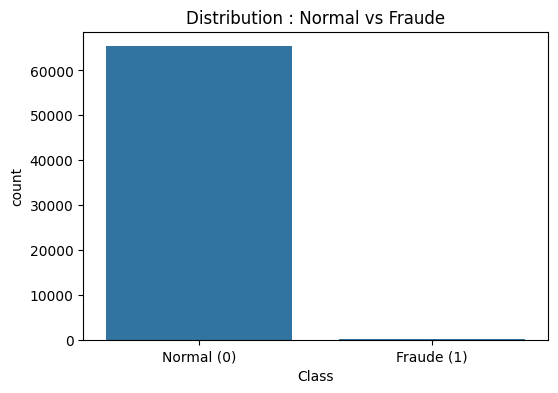

In [8]:
print('Distribution des classes:')
print(df['Class'].value_counts())
print(f'\nTaux de fraude: {df["Class"].mean()*100:.3f}%')

plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df)
plt.title('Distribution : Normal vs Fraude')
plt.xticks([0, 1], ['Normal (0)', 'Fraude (1)'])
plt.show()

## Cellule 4 — Analyse des features (Boxplot V14 + Corrélation)

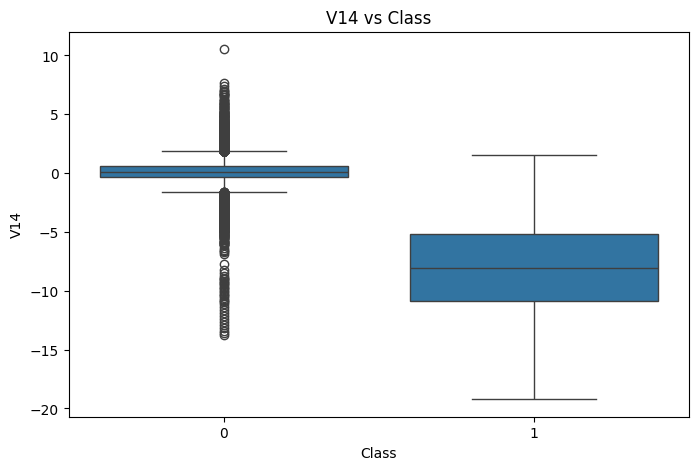

Top 10 features corrélées avec Class:
V17    0.455807
V14    0.406451
V3     0.365453
V10    0.320753
V12    0.318687
V16    0.297476
V7     0.295775
V11    0.217656
V4     0.195418
V18    0.192944
Name: Class, dtype: float64


In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Class', y='V14', data=df)
plt.title('V14 vs Class')
plt.show()

print('Top 10 features corrélées avec Class:')
corr = df.corr(numeric_only=True)['Class'].abs().sort_values(ascending=False)
print(corr[1:11])

## Cellule 5 — Preprocessing (Split + Scaling)

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print(f'Train size : {X_train.shape}')
print(f'Test size  : {X_test.shape}')
print('Preprocessing terminé !')

Train size : (52428, 30)
Test size  : (13107, 30)
Preprocessing terminé !


## Cellule 6 — SMOTE (équilibrage des classes)

In [11]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print('Avant SMOTE:')
print(pd.Series(y_train).value_counts())
print('\nAprès SMOTE:')
print(pd.Series(y_train_res).value_counts())

Avant SMOTE:
Class
0    52301
1      127
Name: count, dtype: int64

Après SMOTE:
Class
0    52301
1    52301
Name: count, dtype: int64


## Cellule 7 — Modèle RandomForest (paramètres optimaux)

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

best_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    random_state=42
)

print('Entraînement en cours...')
best_model.fit(X_train_res, y_train_res)
print('Modèle entraîné !\n')

y_pred = best_model.predict(X_test)
print('=== Classification Report ===')
print(classification_report(y_test, y_pred))

Entraînement en cours...
Modèle entraîné !

=== Classification Report ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13065
           1       0.85      0.83      0.84        42

    accuracy                           1.00     13107
   macro avg       0.93      0.92      0.92     13107
weighted avg       1.00      1.00      1.00     13107



## Cellule 8 — Threshold Tuning (seuil = 0.76)

In [13]:
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred_best = (y_proba > 0.76).astype(int)

print('=== Résultats avec threshold = 0.76 ===')
print(classification_report(y_test, y_pred_best))

=== Résultats avec threshold = 0.76 ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13065
           1       0.89      0.76      0.82        42

    accuracy                           1.00     13107
   macro avg       0.94      0.88      0.91     13107
weighted avg       1.00      1.00      1.00     13107



## Cellule 9 — Confusion Matrix

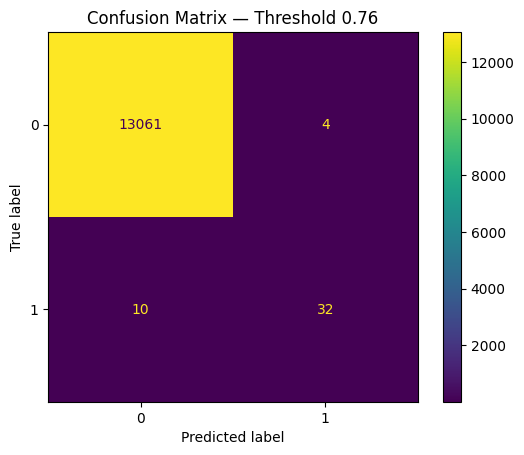

Fraudes détectées (TP) : 32
Fraudes manquées  (FN) : 10
Fausses alarmes   (FP) : 4
Normales correctes(TN) : 13061


In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion Matrix — Threshold 0.76')
plt.show()

print(f'Fraudes détectées (TP) : {cm[1][1]}')
print(f'Fraudes manquées  (FN) : {cm[1][0]}')
print(f'Fausses alarmes   (FP) : {cm[0][1]}')
print(f'Normales correctes(TN) : {cm[0][0]}')

## Cellule 10 — ROC Curve + AUC

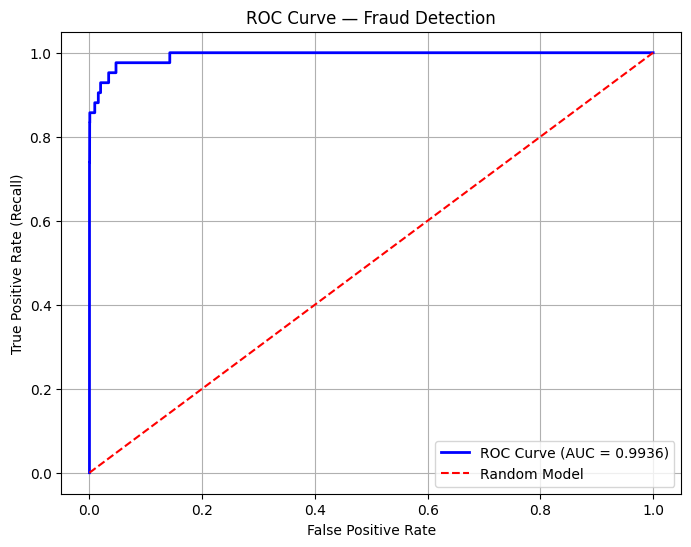

AUC Score: 0.9936


In [15]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve — Fraud Detection')
plt.legend()
plt.grid(True)
plt.show()

print(f'AUC Score: {roc_auc:.4f}')

## Cellule 11 — Feature Importance

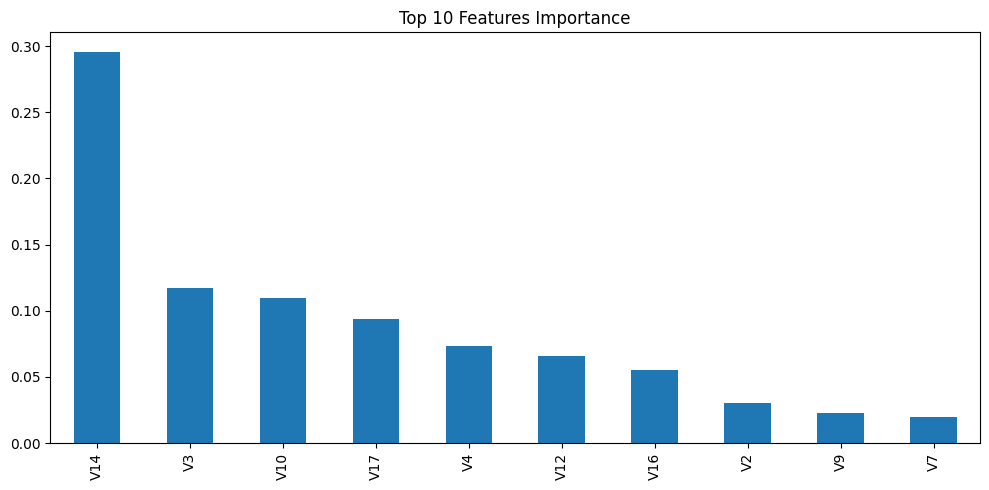

Top 10 features:
V14    0.295552
V3     0.117164
V10    0.109944
V17    0.093420
V4     0.073576
V12    0.065795
V16    0.055432
V2     0.030003
V9     0.022563
V7     0.019606
dtype: float64


In [16]:
feat_imp = pd.Series(
    best_model.feature_importances_,
    index=df.drop('Class', axis=1).columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
feat_imp.head(10).plot(kind='bar')
plt.title('Top 10 Features Importance')
plt.tight_layout()
plt.show()

print('Top 10 features:')
print(feat_imp.head(10))

## Cellule 12 — Sauvegarde du modèle + MLflow

In [17]:
import joblib
import mlflow
import mlflow.sklearn
from sklearn.metrics import roc_auc_score, recall_score, precision_score

# Sauvegarde locale
joblib.dump(best_model, '../models/fraud_model.pkl')
joblib.dump(scaler,     '../models/scaler.pkl')
print('Modèle sauvegardé dans models/ !')

# MLflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('fraud_detection')

with mlflow.start_run(run_name='RandomForest_optimized'):

    mlflow.log_param('n_estimators', 50)
    mlflow.log_param('max_depth', 10)
    mlflow.log_param('threshold', 0.76)

    auc_score = roc_auc_score(y_test, y_proba)
    recall    = recall_score(y_test, y_pred_best)
    precision = precision_score(y_test, y_pred_best)

    mlflow.log_metric('AUC',       auc_score)
    mlflow.log_metric('Recall',    recall)
    mlflow.log_metric('Precision', precision)

    mlflow.sklearn.log_model(best_model, name='model')

    print(f'AUC       : {auc_score:.4f}')
    print(f'Recall    : {recall:.4f}')
    print(f'Precision : {precision:.4f}')
    print('Expérience enregistrée dans MLflow !')

Modèle sauvegardé dans models/ !


2026/04/09 17:49:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


AUC       : 0.9936
Recall    : 0.7619
Precision : 0.8889
Expérience enregistrée dans MLflow !
